# Lab 9: Report

## Three-Point Bending Test of Glass

The main objective of this lab is to understand the testing methods and related challenges for determining the mechanical properties of brittle materials, such as glasses and ceramics.

Recommended reading: Calister, *Materials Science and Engineering: An Introduction*, Chapter 12.8-12.9

## 1. Import data into the notebook

All data from each seciton has been compiled into a single .csv file. Import that data as a pandas dataframe.

In [154]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [155]:
#import the data from the csv. Ignore the first column
df = pd.read_csv('GlassFractureDataCleaned.csv', skiprows=1, usecols=[1,2,4],
                 names=["Label", "Dia / mm", "Load / N"])

# define the span used to collect the data in meters
SPAN = 50.8/1000  

# normalize all Labels to lowercase to make case-insensitive

df["Label"] = df["Label"].str.lower()

df.head()

,Label,Dia / mm,Load / N
0,uncoated,8.001,799.490
1,uncoated,8.001,664.500
2,uncoated,8.077,644.134
3,uncoated,8.052,862.570
4,uncoated,4.166,94.278


## 2. Group data and calculate the flexural strength


Each sample must be split up according to the group it belongs to based on:
- Coating
- Diameter

The code below specifies the condition each sample must meet to be part of the same group. It then assigns a group number 1 through 4 to each sample. If a sample can't be identified it's put into group 0.

In [ ]:
conditions = [
    (df['Label'] == 'uncoated') & (df['Dia / mm'] >= 3) & (df['Dia / mm'] <= 5),
    (df['Label'] == 'coated') & (df['Dia / mm'] >= 3) & (df['Dia / mm'] <= 5),
    (df['Label'] == 'uncoated') & (df['Dia / mm'] >= 7) & (df['Dia / mm'] <= 9),
    (df['Label'] == 'coated') & (df['Dia / mm'] >= 7) & (df['Dia / mm'] <= 9)
]

df['group'] = np.select(condlist = conditions, choicelist = [1, 2, 3, 4], default=0)
for i in np.unique(df["group"]):
    group_count = (df["group"] == i).sum()
    print(f"Group {i}, {group_count} entries:")
    display(df[df['group'] == i].head(3))
    print("\n")

The glass rods were loaded into a 3-point bend test and loaded until fracture. Write the equation below to caculate maximum tensile stress in the glass rod based on the load applied and the specimen geometry. Define the variables used

$$\sigma_\mathrm{fs}=...$$



In the code cell below calculate the flexural strength in GPa. Round to appropriate significant figures.

**Functions for your code**:

- `.round(n)`: round to n decimal places

**Variables for your code**:

- `df['Load / N']`: Load at fracture
- `df['Dia / mm']`: Specimen diameter
- `SPAN`: Span length of test frame

In [156]:
df['Flex Strength / GPa'] = df['Load / N'] * SPAN / (np.pi * (df['Dia / mm']/1000/8)**3 )/(10**9)
df['Flex Strength / GPa'] = df['Flex Strength / GPa'].round(1)
df.head()

,Label,Dia / mm,Load / N,Flex Strength / GPa
0,uncoated,8.001,799.490,12.9
1,uncoated,8.001,664.500,10.7
2,uncoated,8.077,644.134,10.1
3,uncoated,8.052,862.570,13.7
4,uncoated,4.166,94.278,10.8


## 3. Plotting
`YOUR RESPONSE`: (20 points) Plot and compare the distribution of the number of failed specimens as a funciton of flexural strength for all four groups.

1. Decide how many bins to divide each group into
1. Select which plotting style to use (delete the other code)
1. Label the axes
1. Provide a descriptive figure caption

In [158]:
N_BINS = 10 # number of bins for each group

# titles of each group from 1 to 4
titles = {1: 'Uncoated, Diameter 3-5 mm',
          2: 'Coated, Diameter 3-5 mm',
          3: 'Uncoated, Diameter 7-9 mm',
          4: 'Coated, Diameter 7-9 mm'}
    

### Option 1: 4 subplots

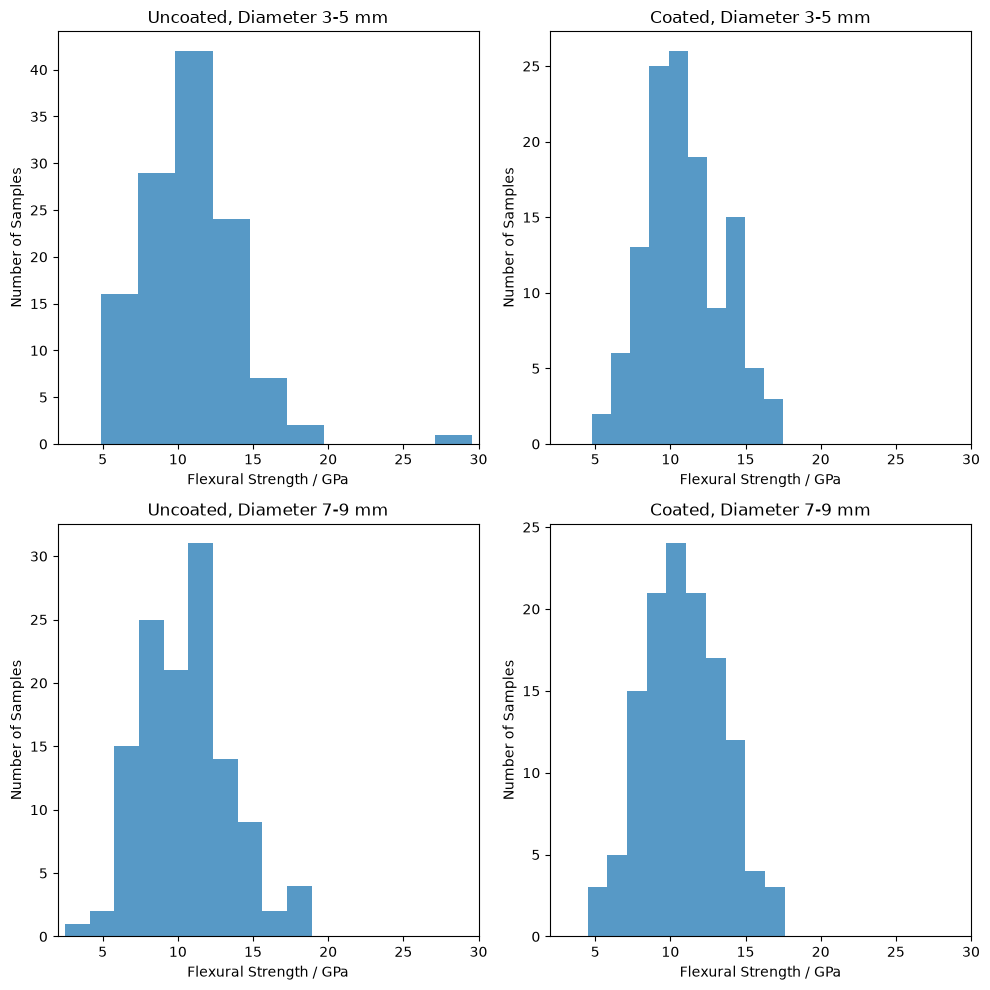

Figure 1. DESCRIPTIVE CAPTION HERE


In [164]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, key in zip(axes.ravel(), titles.keys()):

    #select the data for each group
    group_data = df[df['group'] == key]['Flex Strength / GPa']

    #plot each groups data in a histogram
    counts, bin_edges, patches = ax.hist(group_data, bins=N_BINS, alpha=0.75, label=titles[key])
    ax.set_title(titles[key])
    ax.set_xlabel('Flexural Strength / GPa')
    ax.set_ylabel('Number of Samples')
    ax.set_xlim([2, 30])



plt.tight_layout()
plt.show()

# STUDENT: add a descriptive figure caption. Explain the trends in the caption.
print("Figure 1. DESCRIPTIVE CAPTION HERE")

### Option 2: 1 plot

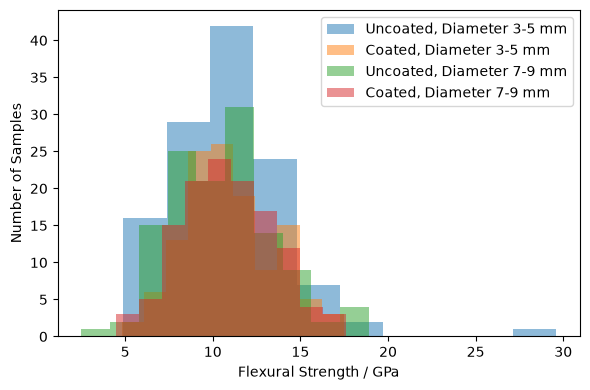

In [ ]:
fig, axes = plt.subplots(figsize=(6, 4))

for key in titles.keys():

    #select the data for each group
    group_data = df[df['group'] == key]['Flex Strength / GPa']

    #plot each groups data in a histogram
    axes.hist(group_data, bins=N_BINS, alpha=(.5))

plt.xlabel('Flexural Strength / GPa')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.legend(titles.values())
plt.show()

# STUDENT: add a descriptive figure caption. Explain the trends in the caption.
print("Figure 1. DESCRIPTIVE CAPTION HERE")

`Your Response`: (20 points) Plot the cumulative probability of failure $P\left(  \sigma_\mathrm{fs}  \right)$ as a funciton of flexural strength for all four test groups.

To determine the probability of failure, forst sort your data points in ascending order of flexural strenght, then determine the probability of failure defined as
$$P\left(  \sigma_\mathrm{fs}  \right) = \frac{n}{N+1}$$
where $n$ is the number of failed samples for a given stress and $N$ is the total number of samples.
